# Algorithm-choice coding bench: the source-data builder (`data.py`), runnable

This notebook is the artifact's `data.py` split into cells, with explanations between them. It runs on a small curated subset of the script's own input.

**What `data.py` does.** It standardises 10 public sources into one `exp_sel_data_out` file, `full_data_out.json` (61,469 examples, 96.2 MB). That file feeds an *algorithm-choice* coding bench, which asks which algorithm an LLM picks for a coding task. For a shortest path the candidates are Dijkstra, BFS, Bellman-Ford and others; for the k-th smallest, quickselect or a heap. The bench also asks where the choice goes when the usual algorithm is banned in the prompt. Every source row becomes one example `{input, output, metadata_*}`, grouped by dataset. Together the sources supply hidden-test seeds, mode-labelled implementations, execution traces, harness and time-limit calibration sets, and a noun bank for context-seed prompts.

**What runs here.** The demo runs the LeetCodeDataset builder on 100 raw rows of [newfacade/LeetCodeDataset](https://huggingface.co/datasets/newfacade/LeetCodeDataset) (Apache-2.0; Xia et al. 2025, arXiv:2504.14655), loaded from `mini_demo_data.json`. The rows include all 20 bench-mapped problems that LeetCodeDataset contains; the map also names 146 (LRU cache) and 295 (median finder), which the source lacks. Among them are the T02 weighted-shortest-path seeds: 743 *Network Delay Time*, 1514 and 1631. The other 80 rows were chosen for difficulty balance and tag diversity. For each bench-mapped problem the builder does two things:
1. It parses every recorded input/output pair into keyword arguments plus an expected value. These are the bench's hidden-test seeds. Records whose "expected output" is really a runtime error message are flagged, not dropped.
2. It re-runs the dataset's own reference solution against its `check()` in an isolated `python -I` subprocess, under memory and CPU limits.

The other nine builders (Mercury, llm-creativity, TheAlgorithms, CLRS-Text, HumanEval+, ENAMEL, concreteness norms, KodCode, XLCoST) are included unchanged, so the script reads as a whole. They need the raw downloads, about 840 MB, which `bash restore.sh` fetches in the artifact folder. The demo therefore defines them but does not call them. The last cell shows how to run the full build.

**Changes to the original code.** Everything not listed here is verbatim:
- Paths are relative to the working directory instead of `__file__`.
- `load_rows()` and `sources_info()` read the loaded demo data when the raw downloads are absent.
- The command line comes from the config cell.
- `data_py_sha256` records the hash of the original `data.py`, because a notebook has no such file.

The results cells at the end check the rebuilt examples against the artifact's published `full_data_out.json`.

In [1]:
# data.py is a uv inline script; its header (kept for reference) pins the three packages it imports:
# #!/usr/bin/env python3
# # /// script
# # requires-python = ">=3.12,<3.13"
# # dependencies = [
# #     "loguru==0.7.3",
# #     "tokenizers==0.23.3",
# #     "huggingface-hub==2.2.0",
# # ]
# # ///
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (same version as data.py)
_pip('loguru==0.7.3')

# Pre-installed on Colab, install locally only, at Colab's versions. tokenizers / huggingface_hub are used only by
# build_concreteness() (Qwen3 token counts), which the demo does not call; pandas / matplotlib are for the results cells.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
__doc__ = """Standardise the downloaded sources into one exp_sel_data_out file (full_data_out.json).

Every row of a source (or of its documented domain subset) becomes one example
{input, output, metadata_*}; examples are grouped by source dataset. Domain handling for the
algorithm-choice coding bench:

* LeetCode-derived rows are mapped to bench tasks (T01-T14, R1-R6). For the bench-mapped
  LeetCodeDataset problems every input_output pair is parsed into keyword arguments plus an
  expected value (case id leetcodedataset:<question_id>:<idx>), and the dataset's own reference
  solution is re-run against its check() in an isolated `python -I` subprocess.
* Implementations (TheAlgorithms, Mercury, XLCoST, KodCode, CLRS traces) carry the
  algorithm modes their path/title/question names (a text match, not a verified label) and, for
  TheAlgorithms, a hand-checked bench mode.
* llm-creativity states no licence: only program paths, the commit and the repository's judge
  labels are stored, never program text.
* The noun bank (Brysbaert concreteness norms) gets Qwen3 token counts and Open English WordNet
  noun classes, and flags candidates for neutral-twin / context-seed nouns.

Only the 10 datasets chosen in the selection stage are built (reasons in README.md and
DATASET_SELECTION.md); scripts/selection_stage_data_all15.py is the 15-source version that was run to
make that choice.

Run:  uv run data.py                                   # all 10 chosen datasets -> full_data_out.json
      uv run data.py --datasets leetcodedataset,mercury # a subset (written to --out)
"""  # notebook: data.py's module docstring, assigned so main() can read its first line

import argparse
import ast
import functools
import hashlib
import json
import re
import resource
import subprocess
import sys
import time
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from loguru import logger

# notebook additions: glob matching over the demo data's file names, and the results cells
import fnmatch

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/dataset-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print({path: len(rows) for path, rows in data["sources"].items()})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Algorithm-choice coding bench: curated raw LeetCodeDataset rows for the data.py demo
{'leetcodedataset/full_newfacade_LeetCodeDataset_default_train.json': 80, 'leetcodedataset/full_newfacade_LeetCodeDataset_default_test.json': 20}


## Configuration

The config cell replaces `data.py`'s command line (`--datasets`, `--out`, `--clrs-per-length`, `--no-verify`, `--max-mb`) with variables. It adds one demo knob, `MAX_ROWS_PER_FILE`: the number of raw rows read from each source file. `None` reads everything, as `data.py` does.

The demo file holds 80 train rows and 20 test rows, and the bench-mapped problems are spread through the train rows in source order. A small cap therefore processes only some of them. The T02 shortest-path seeds 743, 1514 and 1631 come late, at train rows 52, 71 and 73. With all 100 rows the build itself takes a few seconds.

In [5]:
DATASETS = ["leetcodedataset"]  # original: ["all"] = the 10 BUILDERS (needs the raw downloads; the demo data holds LeetCodeDataset rows only)
MAX_ROWS_PER_FILE = None        # raw rows read per source file; None = all, as in data.py (2,641 train + 228 test there; 80 + 20 in the demo file). Tested: 1, 10, None
VERIFY = True                   # re-run the bench-mapped reference solutions against check(); original: True (no --no-verify)
CLRS_PER_LENGTH = 5             # original: 5 (only build_clrs() uses it)
MAX_MB = 95.0                   # original: 95.0 (write numbered parts above this size)
OUT_PATH = Path("demo_data_out.json")  # original: full_data_out.json next to data.py; renamed so the demo never overwrites it

## 1. Setup: paths and logging

`ROOT` is the folder the script works in. `data.py` uses its own folder; the notebook uses the working directory. Raw downloads are expected under `temp/datasets/`. Logging goes to stdout at INFO level and to a rotating `logs/data.log` at DEBUG level.

In [6]:
ROOT = Path.cwd()  # notebook: data.py uses Path(__file__).resolve().parent
DATA = ROOT / "temp" / "datasets"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(LOG_DIR / "data.log", rotation="30 MB", level="DEBUG");  # notebook: ';' hides the returned handler id

## 2. Bench vocabulary: tasks, LeetCode seeds and answer semantics

`BENCH_TASKS` holds the bench's task ids, each with a one-line contract: `T01`–`T14` and the R-series tasks `R1`, `R2`, `R3` and `R6`.

`LEETCODE_BENCH_MAP` says which LeetCode problem seeds which task, and in which role: primary seed, alternate, or related but not reused.

`LEETCODE_ANSWER_SEMANTICS` records what LeetCode's expected output means, because the bench's contract often differs. For example, 215 asks for the k-th *largest* while T03 wants the k-th smallest, and 743 returns a scalar delay while T02 wants a path.

`ERROR_OUTPUT_RE` catches recorded "outputs" that are really runtime error messages.

In [7]:
# ---------------------------------------------------------------------------------------------
# Bench vocabulary (task ids follow the artifact plan; mode ids are this script's vocabulary,
# to be mapped onto the frozen catalogues when the task specs are written).
# ---------------------------------------------------------------------------------------------
BENCH_TASKS = {
    "T01_grid_path": "4-neighbour grid path, any valid path",
    "T02_weighted_shortest_path": "find_path(graph, start, goal), integer weights 1..100, any optimal path",
    "T03_kth_smallest": "k-th smallest of nums",
    "T04_substring_search": "first index of pattern in text without built-in search",
    "T05_two_sum": "indices (i, j), i < j, summing to target",
    "T06_find_duplicate": "the repeated value among n+1 values in 1..n",
    "T07_convex_hull": "strict hull vertices counter-clockwise",
    "T08_fibonacci": "exact F(n), 0 <= n <= 500",
    "T09_lru_cache": "LRUCache(capacity) with get/put",
    "T10_connected_components": "number of components of an undirected graph",
    "T11_longest_increasing_subsequence": "length of the longest strictly increasing subsequence",
    "T12_streaming_median": "median after each insertion",
    "T13_merge_intervals": "merge overlapping intervals",
    "T14_top_k_frequent": "k most frequent values, order free",
    "R1_interval_scheduling": "maximum set of non-overlapping intervals",
    "R2_redundant_connection": "edge whose removal leaves a tree",
    "R3_course_schedule": "any topological order or []",
    "R6_first_occurrence": "first index of target in a sorted array",
}

# LeetCode question id -> (bench task, role). Primary seeds are the problems named in the plan.
LEETCODE_BENCH_MAP: dict[int, tuple[str, str]] = {
    743: ("T02_weighted_shortest_path", "primary_seed"),
    215: ("T03_kth_smallest", "primary_seed"),
    28: ("T04_substring_search", "primary_seed"),
    1: ("T05_two_sum", "primary_seed"),
    287: ("T06_find_duplicate", "primary_seed"),
    587: ("T07_convex_hull", "primary_seed"),
    509: ("T08_fibonacci", "primary_seed"),
    146: ("T09_lru_cache", "primary_seed"),
    547: ("T10_connected_components", "primary_seed"),
    323: ("T10_connected_components", "alternate_seed_exact_signature"),
    300: ("T11_longest_increasing_subsequence", "primary_seed"),
    295: ("T12_streaming_median", "primary_seed"),
    56: ("T13_merge_intervals", "primary_seed"),
    347: ("T14_top_k_frequent", "primary_seed"),
    435: ("R1_interval_scheduling", "primary_seed"),
    684: ("R2_redundant_connection", "primary_seed"),
    210: ("R3_course_schedule", "primary_seed"),
    34: ("R6_first_occurrence", "primary_seed"),
    1971: ("T10_connected_components", "alternate_seed"),
    1631: ("T02_weighted_shortest_path", "alternate_seed"),
    1514: ("T02_weighted_shortest_path", "alternate_seed"),
    1091: ("T01_grid_path", "related_not_reused_8_directional"),
}

# What a LeetCode expected output means for each bench-mapped problem (the bench build converts these).
LEETCODE_ANSWER_SEMANTICS: dict[int, str] = {
    743: "scalar: max over nodes of the shortest distance from k, -1 if any node is unreachable; T02 recomputes a path per (start, goal)",
    215: "scalar: k-th largest; T03 uses k' = n - k + 1 for k-th smallest",
    28: "scalar: first index of needle in haystack or -1",
    1: "pair of indices; LeetCode accepts either order; some generated cases have no solution (expected null), which T05's spec excludes",
    287: "scalar: the duplicated value",
    587: "list of fence points including collinear boundary points, any order; T07 recomputes the strict counter-clockwise hull",
    509: "scalar: F(n) for n <= 30",
    547: "scalar: number of provinces from an adjacency matrix",
    323: "scalar: number of components from (n, edges)",
    300: "scalar: length of the longest strictly increasing subsequence",
    56: "list of merged intervals sorted by start",
    347: "list of the k most frequent values, any order",
    435: "scalar: minimum number of removals; R1 converts to the maximum non-overlapping set",
    684: "edge [u, v]: the last edge in input order that closes a cycle",
    210: "any valid topological order, [] if impossible; expected shows one valid order",
    34: "[first, last] indices of target or [-1, -1]; R6 uses the first",
    1971: "bool: destination reachable from source",
    1631: "scalar: minimum effort (max absolute height step) of a top-left to bottom-right path",
    1514: "float: maximum success probability of a start-to-end path",
    1091: "scalar: shortest 8-directional clear path length or -1",
}
ERROR_OUTPUT_RE = re.compile(r"^\s*(Error|Exception|Traceback)\b", re.I)

## 3. Algorithm-mode lexicon

The *modes* are the algorithm families the bench tells apart, such as `dijkstra`, `bellman_ford_spfa`, `bfs`, `quickselect` and `kmp`. Each mode comes with the tasks it can solve and a regex over lower-cased names, titles or questions. The KodCode, XLCoST and TheAlgorithms builders use the lexicon to tag rows that *name* a mode. These tags are **hints, not verified labels**.

`LEXICON_EXCLUDE` drops homonyms. Boyer-Moore *majority vote* is not Boyer-Moore string search, and a regex or wildcard pattern search is not substring search.

In [8]:
# Text lexicon: mode id, bench tasks it belongs to, regex over lower-cased names/titles/questions.
MODE_LEXICON: list[tuple[str, tuple[str, ...], str]] = [
    ("dijkstra", ("T02_weighted_shortest_path", "T01_grid_path"), r"dijkstra|uniform[\s_-]*cost"),
    ("bellman_ford_spfa", ("T02_weighted_shortest_path",), r"bellman[\s_-]*ford|\bspfa\b|shortest path faster"),
    ("floyd_warshall", ("T02_weighted_shortest_path",), r"floyd[\s_-]*warshall|warshall"),
    ("a_star", ("T01_grid_path", "T02_weighted_shortest_path"), r"\ba\*[\s_-]*(search|algorithm|path)|\ba[\s-]star[\s-]*(search|algorithm|path)|\ba_star\b|\bastar\b"),
    ("bidirectional_search", ("T01_grid_path", "T02_weighted_shortest_path"), r"bi[\s_-]?directional[\s_-]*(search|bfs|breadth|dijkstra|a\*|a[\s_-]?star|astar)"),
    ("zero_one_bfs", ("T02_weighted_shortest_path",), r"\b0[\s_-]?1[\s_-]?bfs|zero[\s_-]one[\s_-]bfs"),
    ("dial", ("T02_weighted_shortest_path",), r"\bdial'?s?[\s_-]*algorithm|bucket[\s_-]*queue"),
    ("bfs", ("T01_grid_path", "T10_connected_components", "R3_course_schedule"), r"breadth[\s_-]*first|\bbfs\b"),
    ("dfs", ("T01_grid_path", "T10_connected_components", "R2_redundant_connection", "R3_course_schedule"), r"depth[\s_-]*first|\bdfs\b"),
    ("topological_sort", ("R3_course_schedule",), r"topolog|\bkahn"),
    ("union_find", ("T10_connected_components", "R2_redundant_connection"), r"union[\s_-]*find|disjoint[\s_-]*set|\bdsu\b"),
    ("kruskal", ("T10_connected_components", "R2_redundant_connection"), r"kruskal"),
    ("connected_components", ("T10_connected_components",), r"connected[\s_-]*component"),
    ("quickselect", ("T03_kth_smallest", "T14_top_k_frequent"), r"quick[\s_-]?select|hoare'?s selection|kth[\s_-]order[\s_-]statistic"),
    ("median_of_medians", ("T03_kth_smallest",), r"median[\s_-]*of[\s_-]*medians"),
    ("kth_smallest_largest", ("T03_kth_smallest",), r"\bk[\s_-]?th[\s_-]+(smallest|largest)|kth[\s_-](smallest|largest)"),
    ("counting_sort", ("T03_kth_smallest",), r"counting[\s_-]*sort"),
    ("heap", ("T03_kth_smallest", "T12_streaming_median", "T14_top_k_frequent"), r"\bheap|priority[\s_-]*queue|heapq"),
    ("naive_string_search", ("T04_substring_search",), r"naive[\s_-]*(string|pattern)|brute[\s_-]*force[\s_-]*(string|pattern)"),
    ("kmp", ("T04_substring_search",), r"knuth[\s_-]*morris|morris[\s_-]*pratt|\bkmp\b|prefix[\s_-]*function|failure[\s_-]*function"),
    ("rabin_karp", ("T04_substring_search",), r"rabin[\s_-]*karp|rolling[\s_-]*hash"),
    ("boyer_moore", ("T04_substring_search",), r"boyer[\s_-]*moore|horspool"),
    ("z_algorithm", ("T04_substring_search",), r"\bz[\s_-]*(algorithm|function|array)\b"),
    ("pattern_search", ("T04_substring_search",), r"pattern[\s_-]*search|substring[\s_-]*search|string[\s_-]*search|find[\s_-]*(all[\s_-]*)?occurrences[\s_-]*of[\s_-]*(a[\s_-]*|the[\s_-]*)?pattern"),
    ("two_sum", ("T05_two_sum",), r"two[\s_-]*sum|pair[\s_-]*(with|whose)[\s_-]*(given[\s_-]*)?sum"),
    ("floyd_cycle_detection", ("T06_find_duplicate",), r"tortoise|floyd'?s?[\s_-]*cycle"),
    ("find_duplicate", ("T06_find_duplicate",), r"find[\s_-]*(the[\s_-]*|a[\s_-]*|all[\s_-]*)?duplicates?\b|duplicate[\s_-]*number"),
    ("graham_scan", ("T07_convex_hull",), r"graham"),
    ("jarvis_march", ("T07_convex_hull",), r"jarvis|gift[\s_-]*wrap"),
    ("monotone_chain", ("T07_convex_hull",), r"monotone[\s_-]*chain|andrew'?s"),
    ("quickhull", ("T07_convex_hull",), r"quick[\s_-]*hull"),
    ("convex_hull", ("T07_convex_hull",), r"convex[\s_-]*hull"),
    ("fibonacci_matrix_power", ("T08_fibonacci",), r"fibonacci.*matrix|matrix.*fibonacci"),
    ("fibonacci_fast_doubling", ("T08_fibonacci",), r"fast[\s_-]*doubling|doubling.*fibonacci|fast[\s_-]*fibonacci"),
    ("fibonacci_closed_form", ("T08_fibonacci",), r"binet|golden[\s_-]*ratio|analytic[\s_-]*fibonacci"),
    ("fibonacci", ("T08_fibonacci",), r"fibonacci"),
    ("lru_cache", ("T09_lru_cache",), r"\blru\b|least[\s_-]*recently[\s_-]*used"),
    ("lis_n_log_n", ("T11_longest_increasing_subsequence",), r"(longest[\s_-]*increasing[\s_-]*subsequence|\blis\b).*(n[\s_]?log|o_nlogn|binary[\s_-]*search|patience)|patience[\s_-]*sort"),
    ("lis", ("T11_longest_increasing_subsequence",), r"longest[\s_-]*increasing[\s_-]*subsequence|\blis\b"),
    ("running_median", ("T12_streaming_median",), r"running[\s_-]*median|median.*(data[\s_-]*)?stream|median[\s_-]*finder|two[\s_-]*heaps"),
    ("merge_intervals", ("T13_merge_intervals",), r"merge[\s_-]*(overlapping[\s_-]*)?intervals|overlapping[\s_-]*intervals"),
    ("top_k_frequent", ("T14_top_k_frequent",), r"top[\s_-]*k\b|k[\s_-]*most[\s_-]*frequent"),
    ("bucket_sort", ("T14_top_k_frequent",), r"bucket[\s_-]*sort"),
    ("activity_selection", ("R1_interval_scheduling",), r"activity[\s_-]*select|interval[\s_-]*scheduling|non[\s_-]*overlapping[\s_-]*intervals"),
    ("binary_search", ("R6_first_occurrence", "T11_longest_increasing_subsequence"), r"binary[\s_-]*search(?![\s_-]*tree)|bisect"),
    ("exponential_search", ("R6_first_occurrence",), r"exponential[\s_-]*search|galloping"),
]
# A mode is not reported when its exclusion pattern also matches (homonymous algorithms).
LEXICON_EXCLUDE: dict[str, str] = {
    "boyer_moore": r"majority|voting|\bvote\b",
    "pattern_search": r"regular[\s_-]*expression|wildcard",
}
_LEXICON = [(m, t, re.compile(p)) for m, t, p in MODE_LEXICON]
_EXCLUDE = {m: re.compile(p) for m, p in LEXICON_EXCLUDE.items()}

## 4. Hand-checked labels, cross-source maps, structural markers and noun-bank filters

- `THEALGORITHMS_CURATED` holds 55 TheAlgorithms/Python files that were read by hand and labelled with (bench task, mode).
- `CLRS_LINKS` lists the 15 CLRS-30 algorithms that implement a bench mode.
- `LLM_CREATIVITY_T02` maps the blind-judge `lineage_minor` labels of the 225 `find_path` programs in [llm-creativity](https://github.com/DrejcPesjak/llm-creativity) onto T02 modes. As the plan says, BFS, DFS and beam search count as `other`. `FINGERPRINT_AXES` names the repository's 11 judge axes.
- `CODE_MARKERS` and `IO_HACK_RE` are regexes over Mercury's human solutions. They flag structure (heapq, bisect, OrderedDict, ...) and stdout or `user.out` hacks, as hints for labellers.
- `CONCRETE_LEXFILES`, `CS_TERMS` and `SENSITIVE_TERMS` filter the neutral-noun bank. That bank feeds context-seed prompts such as `seed=(horse chair roof love)`, so it excludes programming-loaded and sensitive words.

In [9]:
# Hand-checked TheAlgorithms files -> (bench task, mode). Read in this step; see README.md.
THEALGORITHMS_CURATED: dict[str, tuple[str, str]] = {
    "graphs/dijkstra.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_2.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_algorithm.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_alternate.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_binary_grid.py": ("T01_grid_path", "dijkstra"),
    "graphs/bellman_ford.py": ("T02_weighted_shortest_path", "bellman_ford_spfa"),
    "graphs/graphs_floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "dynamic_programming/floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "graphs/bi_directional_dijkstra.py": ("T02_weighted_shortest_path", "bidirectional_search"),
    "graphs/breadth_first_search_zero_one_shortest_path.py": ("T02_weighted_shortest_path", "zero_one_bfs"),
    "graphs/a_star.py": ("T01_grid_path", "a_star"),
    "graphs/bidirectional_a_star.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/bidirectional_breadth_first_search.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/breadth_first_search_shortest_path.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search_shortest_path_2.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search.py": ("T10_connected_components", "bfs"),
    "graphs/breadth_first_search_2.py": ("T10_connected_components", "bfs"),
    "graphs/depth_first_search.py": ("T10_connected_components", "dfs"),
    "graphs/depth_first_search_2.py": ("T10_connected_components", "dfs"),
    "graphs/connected_components.py": ("T10_connected_components", "dfs"),
    "data_structures/disjoint_set/disjoint_set.py": ("T10_connected_components", "union_find"),
    "data_structures/disjoint_set/alternate_disjoint_set.py": ("T10_connected_components", "union_find"),
    "graphs/g_topological_sort.py": ("R3_course_schedule", "topological_sort"),
    "searches/quick_select.py": ("T03_kth_smallest", "quickselect"),
    "divide_and_conquer/kth_order_statistic.py": ("T03_kth_smallest", "quickselect"),
    "data_structures/arrays/kth_largest_element.py": ("T03_kth_smallest", "quickselect"),
    "searches/median_of_medians.py": ("T03_kth_smallest", "median_of_medians"),
    "sorts/counting_sort.py": ("T03_kth_smallest", "counting_sort"),
    "strings/naive_string_search.py": ("T04_substring_search", "naive_string_search"),
    "strings/knuth_morris_pratt.py": ("T04_substring_search", "kmp"),
    "strings/prefix_function.py": ("T04_substring_search", "kmp"),
    "strings/rabin_karp.py": ("T04_substring_search", "rabin_karp"),
    "strings/boyer_moore_search.py": ("T04_substring_search", "boyer_moore"),
    "strings/boyer_moore_horspool.py": ("T04_substring_search", "boyer_moore"),
    "strings/z_function.py": ("T04_substring_search", "z_algorithm"),
    "maths/two_sum.py": ("T05_two_sum", "two_sum_hash_map"),
    "data_structures/linked_list/floyds_cycle_detection.py": ("T06_find_duplicate", "floyd_cycle_detection"),
    "geometry/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "other/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "geometry/jarvis_march.py": ("T07_convex_hull", "jarvis_march"),
    "divide_and_conquer/convex_hull.py": ("T07_convex_hull", "divide_and_conquer_hull"),
    "maths/fibonacci.py": ("T08_fibonacci", "fibonacci_several_variants"),
    "dynamic_programming/fibonacci.py": ("T08_fibonacci", "fibonacci_iteration_table"),
    "dynamic_programming/fast_fibonacci.py": ("T08_fibonacci", "fibonacci_fast_doubling"),
    "matrix/nth_fibonacci_using_matrix_exponentiation.py": ("T08_fibonacci", "fibonacci_matrix_power"),
    "other/lru_cache.py": ("T09_lru_cache", "dict_doubly_linked_list"),
    "dynamic_programming/longest_increasing_subsequence.py": ("T11_longest_increasing_subsequence", "lis_recursive"),
    "dynamic_programming/longest_increasing_subsequence_iterative.py": ("T11_longest_increasing_subsequence", "lis_dp_quadratic"),
    "dynamic_programming/longest_increasing_subsequence_o_nlogn.py": ("T11_longest_increasing_subsequence", "lis_n_log_n"),
    "data_structures/arrays/merge_intervals.py": ("T13_merge_intervals", "sort_and_sweep"),
    "greedy_methods/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "other/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "searches/binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/simple_binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/exponential_search.py": ("R6_first_occurrence", "exponential_search"),
}

# CLRS-30 algorithms that implement a bench mode -> links "task:mode".
CLRS_LINKS: dict[str, list[str]] = {
    "bfs": ["T01_grid_path:bfs", "T10_connected_components:bfs"],
    "dfs": ["T01_grid_path:dfs", "T10_connected_components:dfs"],
    "dijkstra": ["T02_weighted_shortest_path:dijkstra"],
    "bellman_ford": ["T02_weighted_shortest_path:bellman_ford_spfa"],
    "floyd_warshall": ["T02_weighted_shortest_path:floyd_warshall"],
    "dag_shortest_paths": ["T02_weighted_shortest_path:dag_dp"],
    "topological_sort": ["R3_course_schedule:topological_sort"],
    "mst_kruskal": ["T10_connected_components:union_find", "R2_redundant_connection:union_find"],
    "quickselect": ["T03_kth_smallest:quickselect"],
    "naive_string_matcher": ["T04_substring_search:naive_string_search"],
    "kmp_matcher": ["T04_substring_search:kmp"],
    "graham_scan": ["T07_convex_hull:graham_scan"],
    "jarvis_march": ["T07_convex_hull:jarvis_march"],
    "activity_selector": ["R1_interval_scheduling:activity_selection"],
    "binary_search": ["R6_first_occurrence:binary_search"],
}

# llm-creativity judge lineage (lineage_minor) -> T02 mode. The plan maps BFS, DFS and beam search to 'other'.
LLM_CREATIVITY_T02: dict[str, tuple[str, str]] = {
    "dijkstra": ("dijkstra", "dijkstra"),
    "uniform_cost": ("dijkstra", "uniform_cost"),
    "bidirectional_dijkstra": ("bidirectional_search", "bidirectional_dijkstra"),
    "bellman_ford": ("bellman_ford_spfa", "bellman_ford"),
    "spfa": ("bellman_ford_spfa", "spfa"),
    "floyd_warshall": ("floyd_warshall", "floyd_warshall"),
    "dial_bucket": ("dial", "dial_bucket"),
    "astar": ("a_star", "astar"),
    "greedy_best_first": ("a_star", "greedy_best_first"),
    "bidirectional_astar": ("bidirectional_search", "bidirectional_astar"),
    "bfs": ("other", "bfs"),
    "bidirectional_bfs": ("other", "bidirectional_bfs"),
    "dfs": ("other", "dfs"),
    "beam": ("other", "beam"),
    "random_walk_traversal": ("other", "random_walk_traversal"),
    "hybrid": ("other", "hybrid"),
}
FINGERPRINT_AXES = ("trajectory", "stochasticity", "coverage", "heuristic", "frontier", "state_scope",
                    "backtracking", "memory", "adaptation", "topology", "learning")

# Structural markers (regex over code) reported for human solutions; a hint for labellers, not a label.
CODE_MARKERS = {
    "heapq": r"\bheap(push|pop|ify|replace|pushpop)\b|\bnsmallest\b|\bnlargest\b",
    "sort": r"\bsorted\(|\.sort\(",
    "bisect": r"\bbisect\w*\(|\binsort\w*\(",
    "ordered_dict": r"OrderedDict|move_to_end",
    "deque": r"\bdeque\(",
    "counter": r"\bCounter\(",
    "linked_nodes": r"\.prev\b|\.next\b",
    "recursion_cache": r"@(functools\.)?(lru_)?cache\b",
    "set": r"\bset\(\)|\bset\(",
    "two_pointers": r"\bwhile\s+\w+\s*<\s*\w+\s*:",
}
IO_HACK_RE = re.compile(r"sys\.stdout|open\(\s*['\"]user\.out|\bstdin\b|atexit")

# Neutral-noun bank filters for concreteness_nouns.
CONCRETE_LEXFILES = {"noun.artifact", "noun.animal", "noun.plant", "noun.food", "noun.object", "noun.substance"}
CS_TERMS = {  # data-structure / programming words, which would not be neutral next to a coding task
    "tree", "graph", "heap", "stack", "queue", "list", "array", "map", "set", "table", "node", "path", "key",
    "bucket", "pointer", "matrix", "string", "window", "hash", "grid", "edge", "vertex", "link", "chain", "net",
    "network", "file", "record", "cell", "block", "index", "code", "program", "computer", "keyboard", "mouse",
    "screen", "disk", "bit", "byte", "bridge", "root", "leaf", "branch", "cache", "web", "pipe", "port", "socket",
    "frame", "box", "ladder", "wheel", "lock", "token", "number", "letter", "word", "page", "book", "card", "deck",
    "dial", "python", "java", "ruby", "perl", "pearl", "cookie", "bug", "virus", "worm", "shell", "server", "client",
    "terminal", "cloud", "log", "thread", "trunk", "chip", "chips", "cable", "wire", "router", "monitor", "printer",
    "laptop", "tablet", "robot", "bot", "spider", "crawler", "sandbox", "pipeline", "console", "memory", "register",
    "folder", "compass", "anchor", "badge", "label", "tag", "rope", "knot", "line", "corner", "basket",
}
SENSITIVE_TERMS = {
    "breast", "breasts", "penis", "vagina", "nipple", "nipples", "condom", "tampon", "bra", "panties", "underwear",
    "bikini", "butt", "buttocks", "testicle", "testicles", "semen", "sperm", "urine", "feces", "poop", "vomit", "diaper",
    "toilet", "gun", "rifle", "pistol", "bullet", "bomb", "grenade", "knife", "dagger", "sword", "noose", "coffin",
    "corpse", "skull", "syringe", "needle", "cigarette", "cigar", "joint", "beer", "whiskey", "vodka", "wine", "liquor",
    "booze", "cocaine", "heroin", "marijuana", "blood", "wound", "tumor", "cancer", "nazi", "slave", "whip",
    "whisky", "rum", "gin", "tequila", "lager", "champagne", "brandy", "cocktail", "pills", "pill", "drugs", "weed",
    "bra", "lingerie", "thong", "jail", "prison", "cage", "handcuffs", "chain", "grave", "tombstone", "casket",
}

## 5. Helpers: loading source rows, matching the lexicon, checking that code parses

`load_rows()` is the one function whose input changes in the notebook. When the raw downloads are absent (no `temp/datasets/`, as on Colab), its "files" are the keys of the loaded `mini_demo_data.json`, matched with the same glob patterns and natural sort order. In a restored artifact folder it reads the disk exactly as `data.py` does. Either way it applies the `MAX_ROWS_PER_FILE` cap.

`named_modes()` and `tasks_of()` apply the lexicon. `parses_py312()` tests whether third-party code parses under Python 3.12, silencing the `SyntaxWarning`s that invalid escape sequences raise.

In [10]:
# ---------------------------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------------------------
def load_rows(pattern: str) -> list[dict]:
    """Load full_*.json files (and split parts) matching a glob under temp/datasets, in natural order."""
    if not DATA.is_dir():  # notebook: no raw downloads here, so the "files" are the keys of the loaded demo data
        names = sorted((k for k in data["sources"] if fnmatch.fnmatch(k, pattern)),
                       key=lambda k: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", Path(k).name)])
        if not names:
            raise FileNotFoundError(f"no files match temp/datasets/{pattern}; the demo data holds {list(data['sources'])}")
        return [r for k in names for r in data["sources"][k][:MAX_ROWS_PER_FILE]]
    files = sorted(DATA.glob(pattern), key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", p.name)])
    files = [f for f in files if f.is_file()]
    if not files:
        raise FileNotFoundError(f"no files match temp/datasets/{pattern}; run scripts/download_all.py")
    rows: list[dict] = []
    for f in files:
        rows.extend(json.loads(f.read_text())[:MAX_ROWS_PER_FILE])  # notebook: [:MAX_ROWS_PER_FILE] (None = all, as in data.py)
    return rows


def named_modes(text: str) -> list[str]:
    t = text.lower()
    return [m for m, _, rx in _LEXICON if rx.search(t) and not (m in _EXCLUDE and _EXCLUDE[m].search(t))]


def tasks_of(modes: list[str]) -> list[str]:
    tasks = {t for m, ts, _ in _LEXICON if m in modes for t in ts}
    return sorted(tasks)


def parse_quietly(code: str) -> ast.Module:
    """ast.parse without the SyntaxWarnings that third-party code with invalid escapes emits."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", SyntaxWarning)
        return ast.parse(code)


def parses_py312(code: str) -> bool:
    try:
        parse_quietly(code)
        return True
    except (SyntaxError, ValueError):
        return False

## 6. Helpers: parsing recorded LeetCode I/O into Python values

A recorded LeetCodeDataset case is two strings, for example `input = "nums = [3,3], target = 6"` and `output = "[0, 1]"`.
- `parse_kwargs()` wraps the input as a call `f(...)` and reads the keyword arguments from the AST.
- `parse_value()` reads the output the same way.
- `literal()` accepts only literal nodes, including the JSON spellings `true`, `false` and `null`. It never evaluates code, so a malformed record raises `ValueError` and the case is marked `unparseable`.

In [11]:
_NAMES = {"true": True, "false": False, "null": None, "True": True, "False": False, "None": None}


def literal(node: ast.AST) -> object:
    """Convert a literal-only AST node; accepts JSON spellings true/false/null. Raises ValueError otherwise."""
    if isinstance(node, ast.Constant):
        return node.value
    if isinstance(node, (ast.List, ast.Tuple, ast.Set)):
        return [literal(e) for e in node.elts]
    if isinstance(node, ast.Dict):
        return {literal(k): literal(v) for k, v in zip(node.keys, node.values)}
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
        v = literal(node.operand)
        if not isinstance(v, (int, float)):
            raise ValueError("unary op on non-number")
        return -v if isinstance(node.op, ast.USub) else v
    if isinstance(node, ast.Name) and node.id in _NAMES:
        return _NAMES[node.id]
    raise ValueError(f"non-literal node {type(node).__name__}")


def parse_kwargs(s: str) -> dict:
    call = ast.parse(f"f({s})", mode="eval").body
    if not isinstance(call, ast.Call) or call.args:
        raise ValueError("input is not keyword-only")
    return {kw.arg: literal(kw.value) for kw in call.keywords}


def parse_value(s: str) -> object:
    return literal(ast.parse(s.strip(), mode="eval").body)

The next cell is an illustration, not part of `data.py`. It shows the first recorded case of the first demo row, and the lexicon applied to one sentence about path search.

In [12]:
row = data["sources"]["leetcodedataset/full_newfacade_LeetCodeDataset_default_train.json"][0]
io = row["input_output"][0]
print(row["task_id"], io)
print("parse_kwargs ->", parse_kwargs(io["input"]), "| parse_value ->", parse_value(io["output"]))
text = "Find the cheapest route with Dijkstra's algorithm, or run a bidirectional BFS when all weights are equal"
print("named_modes ->", named_modes(text), "| tasks_of ->", tasks_of(named_modes(text)))

two-sum {'input': 'nums = [3,3], target = 6', 'output': '[0, 1]'}
parse_kwargs -> {'nums': [3, 3], 'target': 6} | parse_value -> [0, 1]
named_modes -> ['dijkstra', 'bidirectional_search', 'bfs'] | tasks_of -> ['R3_course_schedule', 'T01_grid_path', 'T02_weighted_shortest_path', 'T10_connected_components']


## 7. Helpers: the sandboxed reference check, paths and source provenance

`run_reference_check()` executes one generated file with `python -I`. The file is the harness prefix, the reference solution, the `check()` function and `print('ALL_OK')`. Isolated mode ignores `PYTHON*` environment variables and the user's site-packages.
- `_limits` caps the child at 2 GB of address space and 60 s of CPU; it is applied through `preexec_fn`.
- A 90 s wall-clock timeout applies on top.
- The check passes only if the child exits with code 0 and its output ends with `ALL_OK`.

`rel()` keeps logged paths relative to `ROOT`. `sources_info()` reads the pinned source revisions from `data_sources.json`. In the notebook it falls back to the copy of the LeetCodeDataset entry that the demo data carries.

In [13]:
def _limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024**3, 2 * 1024**3))
    resource.setrlimit(resource.RLIMIT_CPU, (60, 60))


def run_reference_check(path: Path) -> dict:
    t0 = time.time()
    try:
        p = subprocess.run([sys.executable, "-I", str(path)], cwd=path.parent, capture_output=True, text=True,
                           timeout=90, preexec_fn=_limits)
        ok = p.returncode == 0 and p.stdout.strip().endswith("ALL_OK")
        return {"ok": ok, "sec": round(time.time() - t0, 2), "stderr_tail": p.stderr[-300:]}
    except subprocess.TimeoutExpired:
        return {"ok": False, "sec": round(time.time() - t0, 2), "stderr_tail": "timeout"}


def rel(p: Path) -> str:
    """Path relative to the repository root for logs and metadata (never an absolute server path)."""
    p = p.resolve()
    return p.relative_to(ROOT).as_posix() if p.is_relative_to(ROOT) else p.name


def sources_info() -> dict:
    p = ROOT / "data_sources.json"
    # notebook: without the artifact's data_sources.json, use the leetcodedataset entry carried by the demo data
    return json.loads(p.read_text())["sources"] if p.exists() else data["data_sources"]["sources"]

## 8. Builder: LeetCodeDataset (the builder this demo runs)

The builder reads the train split and then the test split. Each problem becomes one example: `input` is the problem text and `output` is the reference solution.

With `verify=True` it first writes `temp/verify_run/lc_<qid>.py` for every bench-mapped problem. A pool of 5 threads then runs the reference checks.

For a bench-mapped problem, each recorded I/O pair becomes a case `{case_id, status, kwargs, expected}`:
- `case_id` has the form `leetcodedataset:<qid>:<idx>`.
- `status` is `ok`, `unparseable`, or `expected_is_error_message`. The last one is a dataset defect: 73 of the 77 cases of 1971 record an error message as the expected output.

The builder also counts cases whose expected answer is `null` (two-sum has 8 cases with no solution). It stores the `check()` source and the harness prefix for the bench build. Rows not mapped to a task keep the `None` defaults.

In [14]:
# ---------------------------------------------------------------------------------------------
# Builders: one per kept source. Each returns the list of examples.
# ---------------------------------------------------------------------------------------------
def build_leetcodedataset(verify: bool) -> list[dict]:
    rows = []
    for split in ("train", "test"):
        part = load_rows(f"leetcodedataset/full_newfacade_LeetCodeDataset_default_{split}.json")
        rows += [(split, r) for r in part]
    checks: dict[int, dict] = {}
    if verify:
        run_dir = ROOT / "temp" / "verify_run"
        run_dir.mkdir(parents=True, exist_ok=True)
        jobs = {}
        for _, r in rows:
            qid = int(r["question_id"])
            if qid in LEETCODE_BENCH_MAP:
                path = run_dir / f"lc_{qid}.py"
                path.write_text(f"{r['prompt']}\n{r['completion']}\n{r['test']}\ncheck({r['entry_point']})\nprint('ALL_OK')\n")
                jobs[qid] = path
        with ThreadPoolExecutor(max_workers=5) as ex:
            checks = dict(zip(jobs, ex.map(run_reference_check, jobs.values())))
        logger.info(f"LeetCodeDataset reference checks: {sum(c['ok'] for c in checks.values())}/{len(checks)} pass")
    out = []
    for i, (split, r) in enumerate(rows):
        qid = int(r["question_id"])
        task, role = LEETCODE_BENCH_MAP.get(qid, (None, None))
        ex = {
            "input": r["problem_description"],
            "output": r["completion"],
            "metadata_row_index": i,
            "metadata_source_split": split,
            "metadata_question_id": qid,
            "metadata_task_slug": r["task_id"],
            "metadata_difficulty": r["difficulty"],
            "metadata_tags": r["tags"],
            "metadata_entry_point": r["entry_point"],
            "metadata_starter_code": r["starter_code"],
            "metadata_estimated_date": r["estimated_date"],
            "metadata_n_test_cases": len(r["input_output"]),
            "metadata_task_type": "code_generation",
            "metadata_bench_task": task,
            "metadata_bench_role": role,
            "metadata_leetcode_answer_semantics": LEETCODE_ANSWER_SEMANTICS.get(qid),
            "metadata_test_cases_json": None,
            "metadata_n_test_cases_parsed": None,
            "metadata_n_test_cases_error_output": None,
            "metadata_n_expected_null": None,
            "metadata_check_source": None,
            "metadata_harness_prefix": None,
            "metadata_reference_passes_check": None,
        }
        if task is not None:
            cases, n_ok, n_err, n_null = [], 0, 0, 0
            for j, io in enumerate(r["input_output"]):
                case_id = f"leetcodedataset:{qid}:{j}"
                if ERROR_OUTPUT_RE.match(io["output"]):
                    # Dataset defect: the recorded expected output is a runtime error message (e.g. 1971, 1514, 1631).
                    cases.append({"case_id": case_id, "status": "expected_is_error_message", "raw_input": io["input"], "raw_output": io["output"]})
                    n_err += 1
                    continue
                try:
                    kwargs, expected = parse_kwargs(io["input"]), parse_value(io["output"])
                except (SyntaxError, ValueError, TypeError) as e:
                    cases.append({"case_id": case_id, "status": "unparseable", "raw_input": io["input"], "raw_output": io["output"], "parse_error": str(e)[:120]})
                    continue
                cases.append({"case_id": case_id, "status": "ok", "kwargs": kwargs, "expected": expected})
                n_ok += 1
                n_null += expected is None
            ex["metadata_test_cases_json"] = json.dumps(cases, ensure_ascii=False, allow_nan=False)
            ex["metadata_n_test_cases_parsed"] = n_ok
            ex["metadata_n_test_cases_error_output"] = n_err
            ex["metadata_n_expected_null"] = n_null
            ex["metadata_check_source"] = r["test"]
            ex["metadata_harness_prefix"] = r["prompt"]
            if qid in checks:
                ex["metadata_reference_passes_check"] = checks[qid]["ok"]
        out.append(ex)
    return out

## 9. Builders that need the raw downloads (defined here, not called by the demo)

The remaining builders are unchanged. Each one reads its own source from `temp/datasets/`. The llm-creativity and TheAlgorithms builders also run `git rev-parse` on their clones. They therefore run only in a restored artifact folder.

**Mercury** gives one example per human solution of a bench-mapped problem, with runtime, structural markers and an I/O-hack flag. It is the only source of human solutions for the LRU cache (T09) and the streaming median (T12).

**llm-creativity** keeps only the following for each of its 225 T02 `find_path` programs:
- a `repo@commit:path` reference;
- the judge's lineage labels;
- the 11 fingerprint axes.

The repository states no licence, so no program text is copied.

In [15]:
def build_mercury() -> list[dict]:
    out = []
    for split in ("train", "eval"):
        rows = load_rows(f"mercury/full_Elfsong_Mercury_default_{split}.json")
        for i, r in enumerate(rows):
            qid = int(r["id"])
            if qid not in LEETCODE_BENCH_MAP:
                continue
            task, role = LEETCODE_BENCH_MAP[qid]
            q = r["meta_info"]["data"]["question"]
            tags = [t["name"] for t in q.get("topicTags") or []]
            text = "\n".join(r["pretty_content"]) if isinstance(r["pretty_content"], list) else str(r["pretty_content"])
            for k, s in enumerate(r["solutions"]):
                code = s["solution"]
                m = re.match(r"\s*(\d+)\s*ms", str(s.get("runtime", "")))
                out.append({
                    "input": text,
                    "output": code,
                    "metadata_row_index": i,
                    "metadata_source_split": split,
                    "metadata_question_id": qid,
                    "metadata_slug": r["slug_name"],
                    "metadata_difficulty": r["difficulty"],
                    "metadata_topic_tags": tags,
                    "metadata_prompt_skeleton": r["prompt"],
                    "metadata_bench_task": task,
                    "metadata_bench_role": role,
                    "metadata_solution_index": k,
                    "metadata_solution_hash": str(s.get("hash")),
                    "metadata_runtime_ms": int(m.group(1)) if m else None,
                    "metadata_io_hack": bool(IO_HACK_RE.search(code)),
                    "metadata_parses_py312": parses_py312(code),
                    "metadata_structural_markers": [name for name, rx in CODE_MARKERS.items() if re.search(rx, code)],
                    "metadata_task_type": "program_labelling",
                })
    return out


def build_llm_creativity() -> list[dict]:
    base = DATA / "github" / "DrejcPesjak_llm-creativity"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    out = []
    for f in sorted((base / "analysis" / "judge" / "T1").glob("*.json")):
        strategy = f.stem
        for lab in json.loads(f.read_text()):
            idx = int(lab["index"])
            rel = f"runs/T1/{strategy}/{idx:03d}/solution.py"
            minor = lab.get("lineage_minor")
            mode, variant = LLM_CREATIVITY_T02.get(minor, ("other", str(minor)))
            ex = {
                "input": f"DrejcPesjak/llm-creativity@{commit}:{rel}",
                "output": str(minor),
                "metadata_strategy": strategy,
                "metadata_program_index": idx,
                "metadata_program_path": rel,
                "metadata_program_exists": (base / rel).exists(),
                "metadata_commit": commit,
                "metadata_lineage_major": lab.get("lineage_major"),
                "metadata_self_label": lab.get("self_label"),
                "metadata_t02_mode": mode,
                "metadata_t02_variant": variant,
                "metadata_excluded_from_headline": strategy.endswith("confounded"),
                "metadata_bench_task": "T02_weighted_shortest_path",
                "metadata_task_type": "program_label_reference",
                "metadata_redistribution": "paths and judge labels only; the repository states no licence, so program text is not copied",
            }
            for axis in FINGERPRINT_AXES:
                ex[f"metadata_fp_{axis}"] = lab.get(axis)
            out.append(ex)
    return out

**TheAlgorithms/Python** gives every non-test file as an example: the code is the input and the file stem is the output. Each file also gets its hand-checked bench mode, where one exists, and lexicon hints from its path and docstring.

**CLRS-Text** keeps the first `per_length` execution traces per (algorithm, length) for the 15 bench-mode algorithms. These are for tracer tests.

In [16]:
def build_thealgorithms() -> list[dict]:
    base = DATA / "github" / "TheAlgorithms_Python"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    files = sorted(p for p in base.rglob("*.py")
                   if ".git" not in p.parts and not any(part in ("tests", "test") for part in p.parts)
                   and not p.name.startswith("test_") and p.name not in ("__init__.py", "conftest.py"))
    missing = set(THEALGORITHMS_CURATED) - {p.relative_to(base).as_posix() for p in files}
    if missing:
        logger.warning(f"curated TheAlgorithms files not found: {sorted(missing)}")
    out = []
    for i, p in enumerate(files):
        rel = p.relative_to(base).as_posix()
        code = p.read_text(errors="replace")
        task, mode = THEALGORITHMS_CURATED.get(rel, (None, None))
        doc = ""
        try:
            doc = (ast.get_docstring(parse_quietly(code)) or "")[:400]
        except (SyntaxError, ValueError):
            pass
        spaced = rel.replace("/", " ")
        modes = named_modes(f"{spaced} {spaced.replace('_', ' ')} {doc}")
        out.append({
            "input": code,
            "output": p.stem,
            "metadata_row_index": i,
            "metadata_path": rel,
            "metadata_category": rel.split("/")[0],
            "metadata_bench_task": task,
            "metadata_bench_mode": mode,
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_parses_py312": parses_py312(code),
            "metadata_n_lines": code.count("\n") + 1,
            "metadata_commit": commit,
            "metadata_task_type": "algorithm_identification",
        })
    return out


def build_clrs(per_length: int) -> list[dict]:
    rows = load_rows("clrs_text_test/full_smcleish_CLRS-Text-test_default_test_1/full_smcleish_CLRS-Text-test_default_test_1_*.json")
    taken: Counter = Counter()
    out = []
    for i, r in enumerate(rows):
        algo = r["algo_name"]
        if algo not in CLRS_LINKS or taken[(algo, r["length"])] >= per_length:
            continue
        taken[(algo, r["length"])] += 1
        out.append({
            "input": r["question"],
            "output": r["answer"],
            "metadata_row_index": i,
            "metadata_clrs_split": "test_1",
            "metadata_algorithm": algo,
            "metadata_length": r["length"],
            "metadata_bench_links": CLRS_LINKS[algo],
            "metadata_task_type": "execution_trace",
        })
    return out

**XLCoST** stores GeeksforGeeks programs as token streams, with `NEW_LINE`, `INDENT` and `DEDENT` tokens and `▁` for spaces. `detokenize_xlcost()` turns them back into indented Python.

**KodCode** keeps the Algorithm, Data_Structure and Leetcode subsets of its GPT-4o solutions, all of which passed tests.

In [17]:
def detokenize_xlcost(code: str) -> str:
    lines, indent = [], 0
    for chunk in code.split("NEW_LINE"):
        toks = chunk.strip().split()
        while toks and toks[0] in ("INDENT", "DEDENT"):
            indent += 1 if toks.pop(0) == "INDENT" else -1
        line = " ".join(toks).replace("▁", " ").strip()
        if line:
            lines.append("    " * max(indent, 0) + line)
    return "\n".join(lines) + "\n"


def build_xlcost() -> list[dict]:
    out = []
    for split in ("train", "validation", "test"):
        rows = load_rows(f"xlcost_python_program_level/full_codeparrot_xlcost-text-to-code_Python-program-level_{split}.json")
        for i, r in enumerate(rows):
            title = r["text"].split("|")[0].strip()
            code = detokenize_xlcost(r["code"])
            modes = named_modes(title)
            out.append({
                "input": r["text"],
                "output": code,
                "metadata_row_index": i,
                "metadata_source_split": split,
                "metadata_title": title,
                "metadata_named_algorithms": modes,
                "metadata_bench_tasks_named": tasks_of(modes),
                "metadata_detok_parses_py312": parses_py312(code),
                "metadata_task_type": "text_to_code",
            })
    return out


def build_kodcode() -> list[dict]:
    rows = load_rows("kodcode_light_rl_10k/full_KodCode_KodCode-Light-RL-10K_default_train/full_KodCode_KodCode-Light-RL-10K_default_train_*.json")
    out = []
    for i, r in enumerate(rows):
        if r["subset"] not in ("Algorithm", "Data_Structure", "Leetcode"):
            continue
        modes = named_modes(r["question"])
        out.append({
            "input": r["question"],
            "output": r["solution"],
            "metadata_row_index": i,
            "metadata_subset": r["subset"],
            "metadata_question_id": r["question_id"],
            "metadata_style": r["style"],
            "metadata_test": r["test"],
            "metadata_test_info_json": json.dumps(r["test_info"], ensure_ascii=False),
            "metadata_gpt_difficulty": r["gpt_difficulty"],
            "metadata_gpt_pass_percentage": r["gpt_pass_percentage"],
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_task_type": "code_generation",
        })
    return out

**ENAMEL** and **HumanEval+** both cover the 164 HumanEval tasks. In each example the `output` is the complete function, which `join_prompt_body()` assembles from the prompt and the body.
- ENAMEL adds expert-efficient reference solutions and size-levelled input generators, for time-limit calibration.
- HumanEval+ adds the EvalPlus tests, for harness validation.

`FIB_FAMILY` flags the Fibonacci-like tasks, which are relevant to T08.

In [18]:
def join_prompt_body(prompt: str, body: str) -> str:
    """HumanEval-style prompt (signature + docstring) + indented body; ENAMEL prompts lack the final newline."""
    return prompt.rstrip("\n") + "\n" + body


FIB_FAMILY = {"HumanEval/39", "HumanEval/46", "HumanEval/55", "HumanEval/63", "HumanEval/130"}


def build_enamel() -> list[dict]:
    rows = load_rows("enamel/full_q-rz_enamel_default_ENAMEL_HumanEval.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["reference_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_reference_body": r["reference_solution"],
        "metadata_input_generator": r["input_generator"],
        "metadata_input_levels": r["input_levels"],
        "metadata_checker": r["checker"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "efficient_code_generation",
    } for i, r in enumerate(rows)]


def build_humanevalplus() -> list[dict]:
    rows = load_rows("humanevalplus/full_evalplus_humanevalplus_default_test.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["canonical_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_test": r["test"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "code_generation",
    } for i, r in enumerate(rows)]

**Concreteness norms** form the noun bank: 39,954 Brysbaert words with concreteness ratings and SUBTLEX frequency. Each word is joined with two extras:
- its Open English WordNet noun classes, from `oewn_noun_classes()` (cached);
- its Qwen3 token counts, from the `tokenizer.json` of `Qwen/Qwen3-8B` at a pinned commit. No model weights are needed.

A word becomes a `metadata_noun_bank_candidate` only when no exclusion reason applies. It must be a concrete, frequent noun that is a single Qwen3 token, has a concrete WordNet class, and is neither a computing term nor a sensitive word.

In [19]:
def _oewn_lemma(member_id: str) -> str:
    s = re.sub(r"^oewn-", "", member_id)
    s = re.sub(r"-[nvasr](-\d+)?$", "", s)
    return s.replace("-ap-", "'").replace("_", " ")


@functools.cache
def oewn_noun_classes() -> tuple[list[dict], dict[str, set[str]]]:
    rows = load_rows("open_english_wordnet_2023/full_jon-tow_open-english-wordnet-synset-2023_default_train.json")
    nouns = [(i, r) for i, r in enumerate(rows) if r["@partOfSpeech"] == "n"]
    lex: dict[str, set[str]] = defaultdict(set)
    for _, r in nouns:
        for m in r["@members"].split():
            lex[_oewn_lemma(m).lower()].add(r["@lexfile"])
    return [r | {"_row_index": i} for i, r in nouns], lex


QWEN3_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"  # Qwen/Qwen3-8B commit whose tokenizer.json gives the token counts


def qwen3_tokenizer():
    try:
        from huggingface_hub import hf_hub_download
        from tokenizers import Tokenizer

        return Tokenizer.from_file(hf_hub_download("Qwen/Qwen3-8B", "tokenizer.json", revision=QWEN3_REVISION))
    except (OSError, ValueError, ImportError) as e:
        logger.warning(f"Qwen3 tokenizer unavailable ({type(e).__name__}: {e}); token counts set to null")
        return None


def build_concreteness() -> list[dict]:
    rows = load_rows("concreteness_ratings/full_StephanAkkerman_concreteness-ratings_default_train.json")
    _, lex = oewn_noun_classes()
    tok = qwen3_tokenizer()
    out = []
    for i, r in enumerate(rows):
        word = str(r["Word"]).strip()
        n_space = len(tok.encode(" " + word, add_special_tokens=False).ids) if tok else None
        n_bare = len(tok.encode(word, add_special_tokens=False).ids) if tok else None
        freq = r["SUBTLEX"] if isinstance(r["SUBTLEX"], (int, float)) else None
        classes = sorted(lex.get(word.lower(), set()))
        reasons = []
        if r["Dom_Pos"] != "Noun":
            reasons.append("not_noun")
        if r["Bigram"]:
            reasons.append("bigram")
        if not isinstance(r["Conc.M"], (int, float)) or r["Conc.M"] < 4.5:
            reasons.append("concreteness_below_4.5")
        if freq is None or freq < 200:
            reasons.append("subtlex_frequency_below_200")
        if n_space is not None and n_space != 1:
            reasons.append("not_single_qwen3_token")
        if not CONCRETE_LEXFILES & set(classes):
            reasons.append("no_concrete_oewn_noun_class")
        if word.lower() in CS_TERMS:
            reasons.append("computing_term")
        if word.lower() in SENSITIVE_TERMS:
            reasons.append("sensitive_term")
        out.append({
            "input": word,
            "output": f"{r['Conc.M']:.2f}" if isinstance(r["Conc.M"], (int, float)) else str(r["Conc.M"]),
            "metadata_row_index": i,
            "metadata_conc_sd": r["Conc.SD"],
            "metadata_subtlex_frequency": freq,
            "metadata_dominant_pos": r["Dom_Pos"],
            "metadata_bigram": bool(r["Bigram"]),
            "metadata_percent_known": r["Percent_known"],
            "metadata_n_raters": r["Total"],
            "metadata_qwen3_tokens_with_leading_space": n_space,
            "metadata_qwen3_tokens_bare": n_bare,
            "metadata_oewn_noun_lexfiles": classes,
            "metadata_noun_bank_candidate": not reasons,
            "metadata_exclusion_reasons": reasons,
            "metadata_task_type": "lexical_norm_regression",
        })
    return out

## 10. The dataset registry and output splitting

`BUILDERS` lists the 10 chosen datasets in output order. Each entry gives the builder, its source keys in `data_sources.json`, the licence and the row selection. The LeetCodeDataset and CLRS entries have `None` as the builder because `main()` calls those two with arguments.

`split_document()` implements the file-size rule. When the output exceeds `--max-mb`, it is written as numbered parts, and each part is itself a valid `exp_sel_data_out` document.

In [20]:
# The 10 chosen datasets, in output order: name -> (builder, source keys in data_sources.json, licence, row selection)
BUILDERS = {
    "leetcodedataset": (None, ["leetcodedataset"], "Apache-2.0", "all 2,869 problems; parsed test cases and a reference check for the 22 bench-mapped problems"),
    "mercury": (build_mercury, ["mercury"], "CC-BY-NC-4.0", "every human solution of the bench-mapped LeetCode problems (one example per solution)"),
    "llm_creativity": (build_llm_creativity, ["llm_creativity"], "none stated (labels and paths only)", "all judged T1 programs (225), labels only"),
    "thealgorithms_python": (build_thealgorithms, ["thealgorithms_python"], "MIT", "every non-test .py file"),
    "clrs_text": (None, ["clrs_text_test"], "Apache-2.0", "the 15 CLRS-30 algorithms that implement a bench mode; first N traces per (algorithm, length) of split test_1"),
    "humanevalplus": (build_humanevalplus, ["humanevalplus"], "Apache-2.0", "all 164 tasks"),
    "enamel": (build_enamel, ["enamel", "enamel_github"], "Apache-2.0", "all 164 tasks"),
    "concreteness_norms": (build_concreteness, ["concreteness_ratings", "open_english_wordnet_2023"], "MIT mirror of Brysbaert et al. 2014; OEWN CC-BY-4.0", "all 39,954 lemmas, with Qwen3 token counts and OEWN noun classes"),
    "kodcode_algorithmic": (build_kodcode, ["kodcode_light_rl_10k"], "CC-BY-NC-4.0", "rows of the Algorithm, Data_Structure and Leetcode subsets"),
    "xlcost_python": (build_xlcost, ["xlcost_python_program_level"], "CC-BY-SA-4.0", "all Python program-level rows (train/validation/test), code detokenised"),
}


def split_document(doc: dict, out_dir: Path, stem: str, max_bytes: int) -> list[Path]:
    """aii-file-size-limit: write <stem>/<stem>_<k>.json parts, each a valid exp_sel_data_out document."""
    out_dir.mkdir(parents=True, exist_ok=True)
    parts: list[list[dict]] = [[]]
    size = 0
    for ds in doc["datasets"]:
        chunk: list[dict] = []
        for ex in ds["examples"]:
            b = len(json.dumps(ex, ensure_ascii=False).encode()) + 2
            if size + b > max_bytes and (chunk or parts[-1]):
                if chunk:
                    parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
                parts.append([])
                chunk, size = [], 0
            chunk.append(ex)
            size += b
        if chunk:
            parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
    paths = []
    for k, datasets in enumerate(parts, start=1):
        p = out_dir / f"{stem}_{k}.json"
        p.write_text(json.dumps({"metadata": doc["metadata"] | {"part": k, "n_parts": len(parts)}, "datasets": datasets}, ensure_ascii=False, allow_nan=False))
        paths.append(p)
    return paths

## 11. `main()`: build, mark duplicates, validate, summarise, write

For each selected dataset, `main()` takes four steps:
1. It calls the builder.
2. It marks exact `(input, output)` repeats with `metadata_duplicate_of`, the index of the first copy.
3. It rejects malformed examples: `input` and `output` must be strings, and every other key must have the form `metadata_*`.
4. It records a per-dataset summary: count, size, licence, selection, source revisions and task types.

It then writes a single document whose top-level metadata carries the bench vocabulary.

Notebook changes in this cell: the argument list comes from the config cell, and `data_py_sha256` takes the original script's hash from the demo data.

In [21]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    ap.add_argument("--datasets", default="all", help="'all' (the 10 chosen datasets, default) or a comma list of names")
    ap.add_argument("--out", type=Path, default=ROOT / "full_data_out.json")
    ap.add_argument("--clrs-per-length", type=int, default=5)
    ap.add_argument("--no-verify", action="store_true", help="skip re-running LeetCodeDataset reference checks")
    ap.add_argument("--max-mb", type=float, default=95.0, help="split the output above this size (aii-file-size-limit)")
    # notebook: the command line comes from the config cell (data.py: args = ap.parse_args())
    args = ap.parse_args(["--datasets", ",".join(DATASETS), "--out", str(OUT_PATH), "--clrs-per-length", str(CLRS_PER_LENGTH),
                          "--max-mb", str(MAX_MB)] + ([] if VERIFY else ["--no-verify"]))

    names = list(BUILDERS) if args.datasets == "all" else args.datasets.split(",")
    unknown = [n for n in names if n not in BUILDERS]
    if unknown:
        raise ValueError(f"unknown dataset names: {unknown}; choose from {list(BUILDERS)}")
    info = sources_info()
    datasets, summary = [], {}
    for name in names:
        t0 = time.time()
        builder, keys, licence, selection = BUILDERS[name]
        try:
            if name == "leetcodedataset":
                examples = build_leetcodedataset(verify=not args.no_verify)
            elif name == "clrs_text":
                examples = build_clrs(args.clrs_per_length)
            else:
                examples = builder()
        except (FileNotFoundError, KeyError, ValueError, json.JSONDecodeError, subprocess.CalledProcessError) as e:
            logger.error(f"{name}: failed ({type(e).__name__}: {e})")
            raise
        if not examples:
            raise ValueError(f"{name}: produced no examples")
        first_seen: dict[str, int] = {}
        for idx, ex in enumerate(examples):  # sources contain a few exact (input, output) repeats; point at the first copy
            h = hashlib.sha1((ex["input"] + "\x00" + ex["output"]).encode()).hexdigest()
            ex["metadata_duplicate_of"] = first_seen.get(h)
            first_seen.setdefault(h, idx)
        bad = [i for i, ex in enumerate(examples) if not isinstance(ex["input"], str) or not isinstance(ex["output"], str)
               or any(not (k in ("input", "output") or re.fullmatch(r"metadata_[a-zA-Z_][a-zA-Z0-9_]*", k)) for k in ex)]
        if bad:
            raise ValueError(f"{name}: {len(bad)} malformed examples, first index {bad[0]}")
        datasets.append({"dataset": name, "examples": examples})
        nbytes = sum(len(json.dumps(ex, ensure_ascii=False).encode()) for ex in examples)
        summary[name] = {
            "n_examples": len(examples), "mb": round(nbytes / 1e6, 2), "licence": licence, "selection": selection,
            "sources": {k: {"repo_or_url": info.get(k, {}).get("repo") or info.get(k, {}).get("url"),
                            "revision": info.get(k, {}).get("revision"), "paper": info.get(k, {}).get("paper")} for k in keys},
            "task_types": dict(Counter(ex.get("metadata_task_type") for ex in examples)),
        }
        logger.info(f"{name}: {len(examples)} examples, {nbytes / 1e6:.1f} MB, {time.time() - t0:.1f}s")

    doc = {
        "metadata": {
            "title": "Algorithm-choice coding bench: standardised source data",
            "description": "Sources for building and validating a Python algorithm-choice bench (hidden-test seeds, "
                           "mode-labelled implementations, execution traces, harness/calibration sets, noun bank). "
                           "One example per source row; grouped by dataset.",
            "schema": "exp_sel_data_out",
            "generated_by": "data.py",
            "data_py_sha256": data["metadata"]["data_py_sha256"],  # notebook: the original data.py's hash (data.py hashes Path(__file__))
            "datasets_included": names,
            "bench_tasks": BENCH_TASKS,
            "leetcode_bench_map": {str(k): {"bench_task": v[0], "role": v[1]} for k, v in LEETCODE_BENCH_MAP.items()},
            "mode_lexicon": [{"mode": m, "bench_tasks": list(t), "regex": p, "exclude": LEXICON_EXCLUDE.get(m)} for m, t, p in MODE_LEXICON],
            "summary": summary,
            "notes": [
                "metadata_named_algorithms / metadata_bench_tasks_named come from a regex over names, titles or questions: hints, not verified labels.",
                "LeetCode problem text is included as source data only; bench specs must be written in new wording.",
                "llm-creativity programs are referenced by path at a pinned commit; fetch them with scripts/download_all.py.",
            ],
        },
        "datasets": datasets,
    }
    text = json.dumps(doc, ensure_ascii=False, allow_nan=False)
    if len(text.encode()) > args.max_mb * 1e6:
        parts = split_document(doc, args.out.parent / args.out.stem, args.out.stem, int(args.max_mb * 1e6))
        if args.out.exists():
            args.out.unlink()
        logger.info(f"output {len(text.encode()) / 1e6:.1f} MB > {args.max_mb} MB: wrote {len(parts)} parts under {rel(args.out.parent / args.out.stem)}/")
    else:
        args.out.write_text(text)
        logger.info(f"wrote {rel(args.out)} ({len(text.encode()) / 1e6:.1f} MB, {sum(len(d['examples']) for d in datasets)} examples, {len(datasets)} datasets)")

## 12. Run

`data.py` ends with the usual entry point. A notebook's `__name__` is also `"__main__"`, so the same two lines run the build. The log shows the reference checks, the number of examples built, and the file written to `OUT_PATH`.

In [22]:
if __name__ == "__main__":
    main()

09:04:05|INFO   |LeetCodeDataset reference checks: 20/20 pass


09:04:05|INFO   |leetcodedataset: 100 examples, 0.9 MB, 0.7s


09:04:05|INFO   |wrote demo_data_out.json (0.9 MB, 100 examples, 1 datasets)


## Results

### The written document and the bench-mapped problems

The code below reads back what `main()` wrote. It then tabulates every bench-mapped problem among the processed rows:
- `cases`: recorded I/O pairs;
- `ok`: pairs that became usable hidden-test seeds;
- `error_msg`: pairs whose recorded "expected" value is a runtime error message;
- `unparseable`: pairs that could not be parsed;
- `expected_null`: pairs with no answer;
- `reference_passes`: whether the dataset's reference solution passed its own `check()`.

In [23]:
# Read back what main() wrote (numbered parts if the output exceeded MAX_MB)
parts = [OUT_PATH] if OUT_PATH.exists() else sorted((OUT_PATH.parent / OUT_PATH.stem).glob(f"{OUT_PATH.stem}_*.json"),
                                                    key=lambda p: int(p.stem.rsplit("_", 1)[1]))
docs = [json.loads(p.read_text()) for p in parts]
meta = docs[0]["metadata"]
examples = [ex for d in docs for ds in d["datasets"] if ds["dataset"] == "leetcodedataset" for ex in ds["examples"]]
print(f"{', '.join(p.name for p in parts)}: schema {meta['schema']}, datasets {meta['datasets_included']}, "
      f"{sum(p.stat().st_size for p in parts) / 1e6:.2f} MB")
print("leetcodedataset summary:", json.dumps(meta["summary"]["leetcodedataset"]))
print(f"{len(examples[0])} fields per example:", list(examples[0]))

bench_rows = []
for ex in examples:
    if ex["metadata_bench_task"] is None:
        continue
    status = Counter(c["status"] for c in json.loads(ex["metadata_test_cases_json"]))
    bench_rows.append({"qid": ex["metadata_question_id"], "slug": ex["metadata_task_slug"], "bench_task": ex["metadata_bench_task"],
                       "role": ex["metadata_bench_role"], "difficulty": ex["metadata_difficulty"],
                       "cases": ex["metadata_n_test_cases"], "ok": status["ok"],
                       "error_msg": status["expected_is_error_message"], "unparseable": status["unparseable"],
                       "expected_null": ex["metadata_n_expected_null"], "reference_passes": ex["metadata_reference_passes_check"]})
bench = pd.DataFrame(bench_rows)
print(f"\n{len(examples)} examples, {len(bench)} bench-mapped; "
      f"{int(bench['ok'].sum()) if len(bench) else 0} parsed hidden-test seed cases")
bench

demo_data_out.json: schema exp_sel_data_out, datasets ['leetcodedataset'], 0.93 MB
leetcodedataset summary: {"n_examples": 100, "mb": 0.92, "licence": "Apache-2.0", "selection": "all 2,869 problems; parsed test cases and a reference check for the 22 bench-mapped problems", "sources": {"leetcodedataset": {"repo_or_url": "newfacade/LeetCodeDataset", "revision": "215604aeed660029df7de2fea5a4d7b6ed476a08", "paper": "Xia et al. 2025, arXiv:2504.14655"}}, "task_types": {"code_generation": 100}}
24 fields per example: ['input', 'output', 'metadata_row_index', 'metadata_source_split', 'metadata_question_id', 'metadata_task_slug', 'metadata_difficulty', 'metadata_tags', 'metadata_entry_point', 'metadata_starter_code', 'metadata_estimated_date', 'metadata_n_test_cases', 'metadata_task_type', 'metadata_bench_task', 'metadata_bench_role', 'metadata_leetcode_answer_semantics', 'metadata_test_cases_json', 'metadata_n_test_cases_parsed', 'metadata_n_test_cases_error_output', 'metadata_n_expected_null

,qid,slug,bench_task,role,difficulty,cases,ok,error_msg,unparseable,expected_null,reference_passes
0,1,two-sum,T05_two_sum,primary_seed,Easy,80,80,0,0,8,True
1,28,find-the-index-of-the-first-occurrence-in-a-st...,T04_substring_search,primary_seed,Easy,144,144,0,0,0,True
2,34,find-first-and-last-position-of-element-in-sor...,R6_first_occurrence,primary_seed,Medium,137,137,0,0,0,True
3,56,merge-intervals,T13_merge_intervals,primary_seed,Medium,91,91,0,0,0,True
4,210,course-schedule-ii,R3_course_schedule,primary_seed,Medium,91,91,0,0,0,True
5,215,kth-largest-element-in-an-array,T03_kth_smallest,primary_seed,Medium,78,78,0,0,0,True
6,287,find-the-duplicate-number,T06_find_duplicate,primary_seed,Medium,87,87,0,0,0,True
7,300,longest-increasing-subsequence,T11_longest_increasing_subsequence,primary_seed,Medium,134,134,0,0,0,True
8,323,number-of-connected-components-in-an-undirecte...,T10_connected_components,alternate_seed_exact_signature,Medium,71,71,0,0,0,True
9,347,top-k-frequent-elements,T14_top_k_frequent,primary_seed,Medium,34,34,0,0,0,True


### T02 seeds: what a parsed hidden-test case looks like

The bench's T02 task is `find_path(graph, start, goal)` with integer weights. It is the task where the study tracks which algorithm an LLM picks: Dijkstra, Bellman-Ford, A*, bidirectional search and so on. Its LeetCode seeds are 743, with 1514 and 1631 as alternates. Their answer semantics differ from T02's contract, so the bench build recomputes paths from these inputs. The cell prints the smallest usable case of each seed.

In [24]:
t02 = [ex for ex in examples if ex["metadata_bench_task"] == "T02_weighted_shortest_path"]
for ex in t02:
    cases = [c for c in json.loads(ex["metadata_test_cases_json"]) if c["status"] == "ok"]
    print(f"{ex['metadata_question_id']} {ex['metadata_task_slug']} ({ex['metadata_bench_role']}): "
          f"{len(cases)} usable cases of {ex['metadata_n_test_cases']}")
    print(f"  semantics: {ex['metadata_leetcode_answer_semantics']}")
    c = min(cases, key=lambda c: len(json.dumps(c["kwargs"])))  # the smallest case, readable on one line
    print(f"  {c['case_id']}: kwargs={json.dumps(c['kwargs'])} -> expected={c['expected']}\n")
if not t02:
    print("No T02 seed among the processed rows: set MAX_ROWS_PER_FILE = None (743, 1514 and 1631 are late train rows).")

743 network-delay-time (primary_seed): 100 usable cases of 100
  semantics: scalar: max over nodes of the shortest distance from k, -1 if any node is unreachable; T02 recomputes a path per (start, goal)
  leetcodedataset:743:1: kwargs={"times": [[1, 2, 1]], "n": 2, "k": 1} -> expected=1

1514 path-with-maximum-probability (alternate_seed): 69 usable cases of 70
  semantics: float: maximum success probability of a start-to-end path
  leetcodedataset:1514:10: kwargs={"n": 3, "edges": [[0, 1]], "succProb": [0.5], "start_node": 0, "end_node": 2} -> expected=0

1631 path-with-minimum-effort (alternate_seed): 69 usable cases of 70
  semantics: scalar: minimum effort (max absolute height step) of a top-left to bottom-right path
  leetcodedataset:1631:7: kwargs={"heights": [[1, 1], [1, 1]]} -> expected=0



### Figure: test-case yield per bench-mapped problem, and what was processed

- **(a)** Each bar is one bench-mapped problem, labelled with its bench task. The bar splits its recorded I/O pairs by parse status, and the label at the end gives the reference-check result. Error-message records are rare, apart from 1971, and every reference solution should pass.
- **(b)** All processed rows by difficulty, split into bench-mapped and other problems.

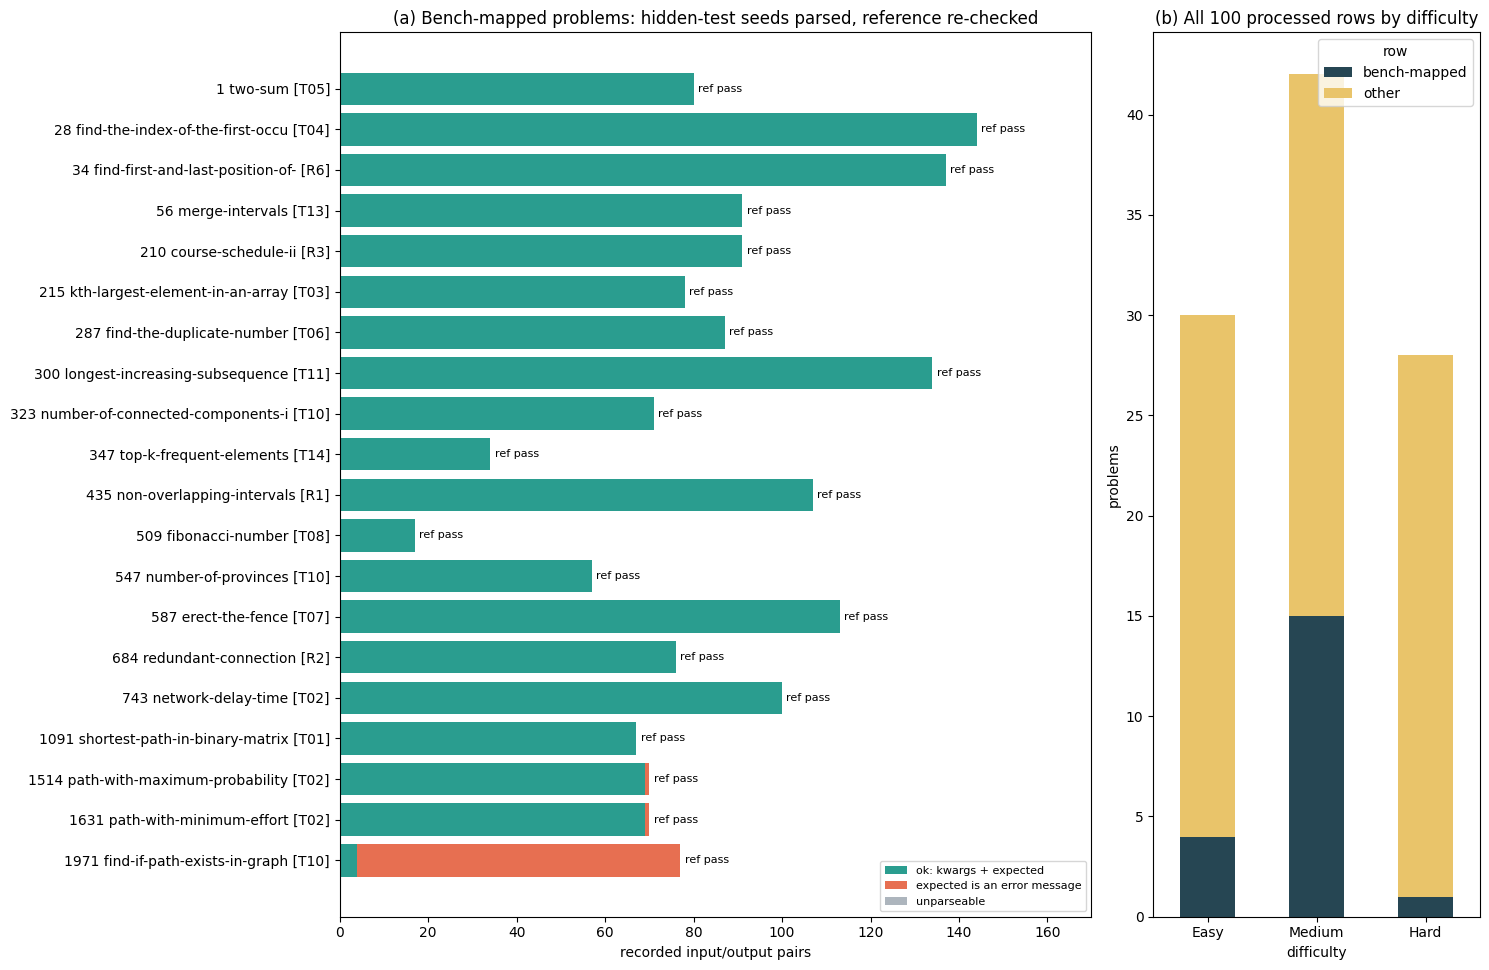

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 1.8 + 0.4 * max(len(bench), 4)), gridspec_kw={"width_ratios": [2.3, 1]})

# (a) per bench-mapped problem: recorded I/O pairs by parse status, plus the reference-check result
if len(bench):
    labels = [f"{q} {s[:32]} [{t.split('_')[0]}]" for q, s, t in zip(bench["qid"], bench["slug"], bench["bench_task"])]
    left = pd.Series(0, index=bench.index)
    for col, color, name in (("ok", "#2a9d8f", "ok: kwargs + expected"),
                             ("error_msg", "#e76f51", "expected is an error message"),
                             ("unparseable", "#adb5bd", "unparseable")):
        ax1.barh(labels, bench[col], left=left, color=color, label=name)
        left = left + bench[col]
    for y, (n, ref) in enumerate(zip(left.tolist(), bench["reference_passes"].tolist())):
        ax1.text(n + 1, y, "ref pass" if ref is True else "ref FAIL" if ref is False else "ref not run", va="center", fontsize=8)
    ax1.invert_yaxis()
    ax1.set_xlim(0, left.max() * 1.18)
    ax1.legend(loc="lower right", fontsize=8)
ax1.set_xlabel("recorded input/output pairs")
ax1.set_title("(a) Bench-mapped problems: hidden-test seeds parsed, reference re-checked")

# (b) composition of all processed rows
comp = pd.crosstab(pd.Series([ex["metadata_difficulty"] for ex in examples], name="difficulty"),
                   pd.Series(["bench-mapped" if ex["metadata_bench_task"] else "other" for ex in examples], name="row"))
comp = comp.reindex(["Easy", "Medium", "Hard"]).fillna(0).astype(int)
comp.plot.bar(stacked=True, ax=ax2, rot=0, color=[{"bench-mapped": "#264653", "other": "#e9c46a"}[c] for c in comp.columns])
ax2.set_title(f"(b) All {len(examples)} processed rows by difficulty")
ax2.set_ylabel("problems")
plt.tight_layout()
plt.show()

### Does the notebook reproduce the published artifact?

For each of its rows, `mini_demo_data.json` stores a SHA-256 fingerprint of the matching example in the artifact's `full_data_out.json`. Two fields are left out of the fingerprint because they depend on a row's position among all 2,869 problems: `metadata_row_index` and `metadata_duplicate_of`.

Recomputing the fingerprints on the rebuilt examples tests whether this run of the original code produces byte-identical examples. That covers the parsed test cases and the reference-check result too. With `VERIFY = False`, the bench-mapped rows differ by design, because their `metadata_reference_passes_check` stays `None`.

In [26]:
POSITIONAL = ("metadata_row_index", "metadata_duplicate_of")  # depend on the row's position among all 2,869 problems
published = data["metadata"]["published_examples"]


def fingerprint(ex: dict) -> str:
    return hashlib.sha256(json.dumps({k: v for k, v in ex.items() if k not in POSITIONAL}, ensure_ascii=False,
                                     sort_keys=True).encode()).hexdigest()


same = {ex["metadata_question_id"]: fingerprint(ex) == published[str(ex["metadata_question_id"])]["sha256"] for ex in examples}
bench_qids = bench["qid"].tolist() if len(bench) else []
print(f"rebuilt examples identical to the published full_data_out.json: {sum(same.values())}/{len(same)} "
      f"(bench-mapped: {sum(same[q] for q in bench_qids)}/{len(bench_qids)})")
print("differing question ids:", [q for q, ok in same.items() if not ok] or "none")
print("row index here -> row index in the full 2,869-row build (first 5):",
      {ex["metadata_row_index"]: published[str(ex["metadata_question_id"])]["metadata_row_index"] for ex in examples[:5]})

rebuilt examples identical to the published full_data_out.json: 100/100 (bench-mapped: 20/20)
differing question ids: none
row index here -> row index in the full 2,869-row build (first 5): {0: 0, 1: 8, 2: 18, 3: 20, 4: 27}


## Running the full build

The full build produces all 10 datasets. Run it inside the artifact's own folder, the one that holds `data.py`, `restore.sh` and `data_sources.json`:

1. Run `bash restore.sh`. It downloads the 15 pinned sources into `temp/datasets/`: about 840 MB, in about 6 minutes.
2. In the config cell set `DATASETS = ["all"]` and `MAX_ROWS_PER_FILE = None`. To replace the published file, also set `OUT_PATH = Path("full_data_out.json")`.
3. Run all cells. `load_rows()` and `sources_info()` now find the downloads, so they read the disk exactly as `data.py` does.

The original run built 61,469 examples in about 25 s; `logs/data.log` has the times. The noun-bank builder also downloads Qwen3's `tokenizer.json` (about 11 MB). Running `uv run data.py` in that folder is equivalent.